In [70]:
import pandas as pd

In [71]:
data=pd.read_csv("customer_tickets_5000.csv")

In [72]:
data.head(10)

,ticket_id,subject,body,channel,customer_tier,created_at,category,urgency,assigned_team,language,resolution_status
0,TKT-001366,Request for custom fields in ticket view,Could you consider adding include JSON as an e...,web_form,pro,2025-04-03T07:41:06Z,feature_request,medium,product_team,en,pending
1,TKT-001137,Request for a clear status update,We rely on this service for daily work. differ...,chat,pro,2025-12-28T23:36:21Z,complaint,medium,success_team,en,open
2,TKT-001842,The issue keeps returning after repair,This has affected our team's work for several ...,phone,free,2025-06-08T19:28:12Z,complaint,high,success_team,en,resolved
3,TKT-002689,Search results are missing recent records,The problem started after the workspace was up...,chat,enterprise,2025-03-26T04:13:29Z,technical_issue,critical,engineering,en,escalated
4,TKT-002491,Tax amount seems incorrect on invoice,I noticed a receipt that never arrived on my a...,phone,free,2025-11-09T04:25:15Z,billing,medium,billing_team,en,pending
5,TKT-004889,Refund has not arrived yet,This started after our plan changed last week....,web_form,enterprise,2025-12-09T16:41:30Z,billing,high,billing_team,en,escalated
6,TKT-004453,Request a copy of my personal information,Could you clarify how to export our workspace ...,chat,pro,2025-01-10T23:38:30Z,data_privacy,medium,compliance_team,en,pending
7,TKT-000273,My card was charged twice this month,This started after our plan changed last week....,chat,free,2025-04-14T18:36:46Z,billing,medium,billing_team,en,resolved
8,TKT-004350,Tax amount seems incorrect on invoice,I was expecting a different amount because the...,email,free,2025-01-29T00:45:43Z,billing,high,billing_team,en,pending
9,TKT-004082,Cancel workspace subscription effective today,Could someone help us remove our paid seats? I...,phone,free,2025-09-28T19:37:20Z,cancellation,medium,billing_team,en,open


In [73]:
data['subject'].value_counts()

subject
Reports download as an empty file                              97
Subscription renewal charged early for my workspace account    93
Invoice total looks higher than expected                       92
Search results are missing recent records                      91
Page displays an error on every refresh                        90
                                                               ..
Support response has taken too long                            44
Cancel workspace subscription effective today                  43
Request for a clear status update                              41
Request export of workspace data                               39
Request to correct profile information                         37
Name: count, Length: 80, dtype: int64

In [74]:
data.columns

Index(['ticket_id', 'subject', 'body', 'channel', 'customer_tier',
       'created_at', 'category', 'urgency', 'assigned_team', 'language',
       'resolution_status'],
      dtype='str')

In [75]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   ticket_id          5000 non-null   str  
 1   subject            5000 non-null   str  
 2   body               5000 non-null   str  
 3   channel            5000 non-null   str  
 4   customer_tier      5000 non-null   str  
 5   created_at         5000 non-null   str  
 6   category           5000 non-null   str  
 7   urgency            5000 non-null   str  
 8   assigned_team      5000 non-null   str  
 9   language           5000 non-null   str  
 10  resolution_status  5000 non-null   str  
dtypes: str(11)
memory usage: 1.7 MB


In [76]:
data['channel'].unique()

<ArrowStringArray>
['web_form', 'chat', 'phone', 'email']
Length: 4, dtype: str

In [77]:
data['customer_tier'].unique()

<ArrowStringArray>
['pro', 'free', 'enterprise']
Length: 3, dtype: str

In [78]:
data['category'].value_counts()

category
technical_issue    835
billing            793
account_access     727
how_to_question    608
data_privacy       528
complaint          511
feature_request    503
cancellation       495
Name: count, dtype: int64

In [79]:
data[data['category']=='cancellation'][['subject','body']][0:5]

,subject,body
9,Cancel workspace subscription effective today,Could someone help us remove our paid seats? I...
12,Please confirm cancellation and final bill,"Our plans have changed, so I would like to end..."
29,End subscription at current billing period,Please close the unused account. We have revie...
34,End subscription at current billing period,"Our plans have changed, so I would like to rem..."
36,Cancel plan after recent team changes,Could someone help us turn off automatic renew...


In [80]:
data['urgency'].unique()

<ArrowStringArray>
['medium', 'high', 'critical', 'low']
Length: 4, dtype: str

In [81]:
data[data['urgency']=='low']['customer_tier'].value_counts()

customer_tier
pro           324
free          279
enterprise     61
Name: count, dtype: int64

In [82]:
data['assigned_team'].unique()

<ArrowStringArray>
[   'product_team',    'success_team',     'engineering',    'billing_team',
 'compliance_team',       'auth_team']
Length: 6, dtype: str

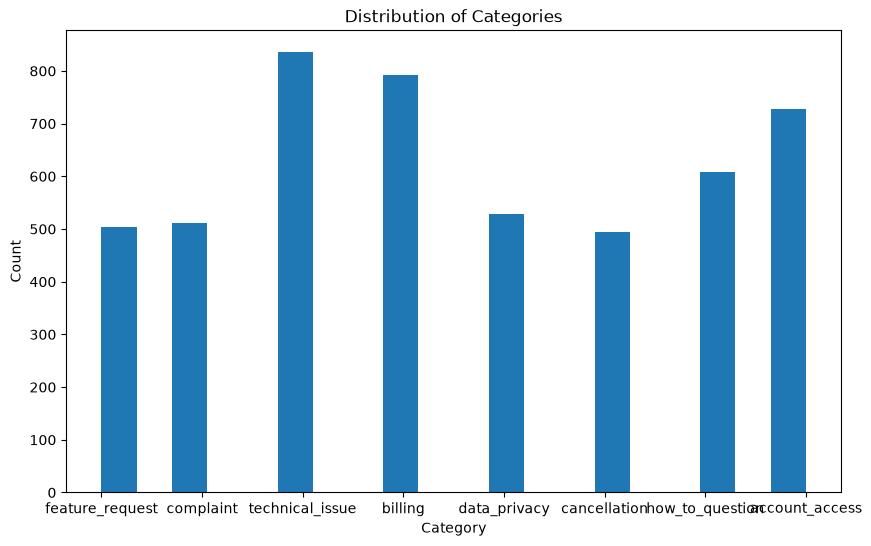

In [83]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.hist(data['category'], bins=20)
plt.xlabel('Category')
plt.ylabel('Count')
plt.title('Distribution of Categories')
plt.show()

In [177]:
data['urgency'].value_counts(normalize=True)

urgency
medium      0.3756
high        0.3566
critical    0.1350
low         0.1328
Name: proportion, dtype: float64

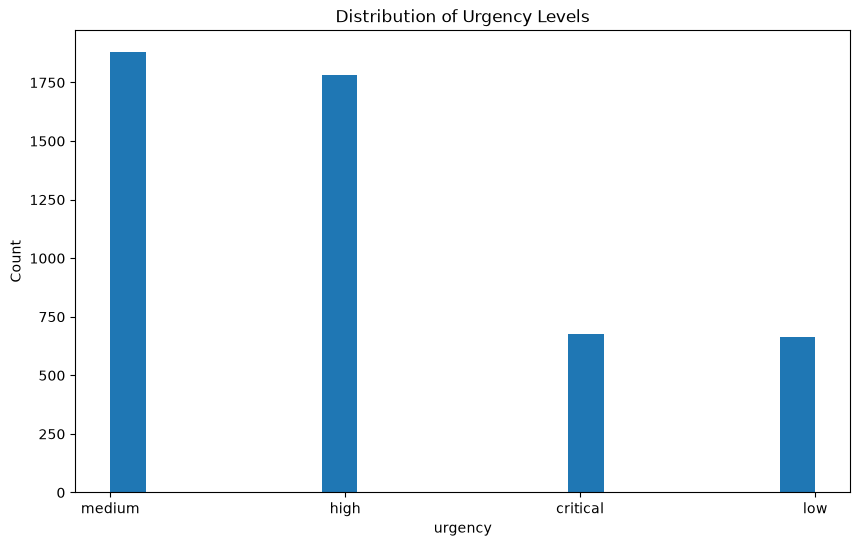

In [176]:
plt.figure(figsize=(10, 6))
plt.hist(data['urgency'], bins=20)
plt.xlabel('urgency')
plt.ylabel('Count')
plt.title('Distribution of Urgency Levels')
plt.show()

In [ ]:
#smote oversampaling on critical and low level urgency data to balance the ditribution


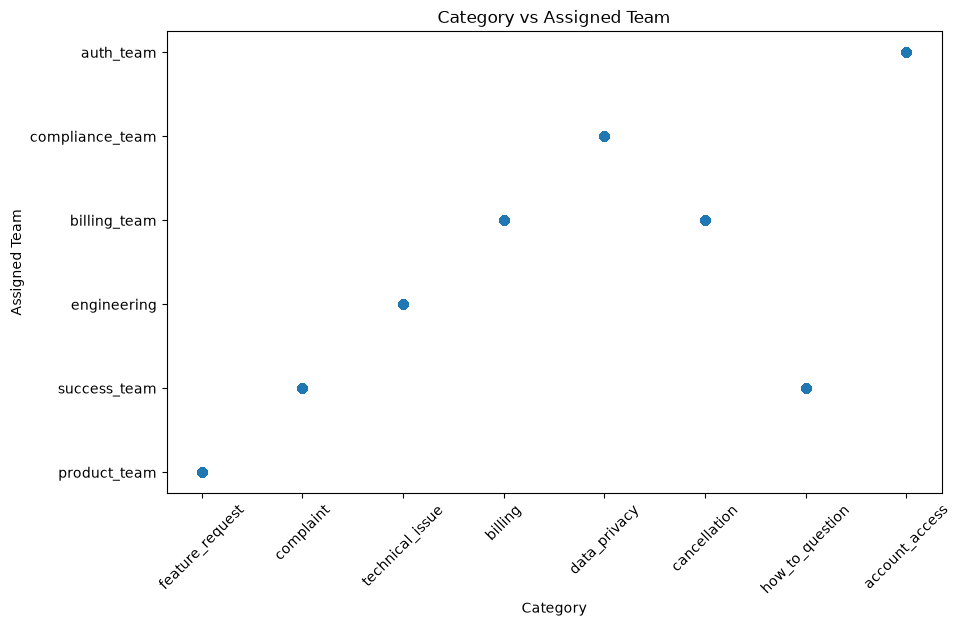

In [84]:
#plot between category and assigned team
plt.figure(figsize=(10, 6))
plt.scatter(data['category'], data['assigned_team'])
plt.xlabel('Category')
plt.ylabel('Assigned Team')
plt.title('Category vs Assigned Team')
plt.xticks(rotation=45)
plt.show()

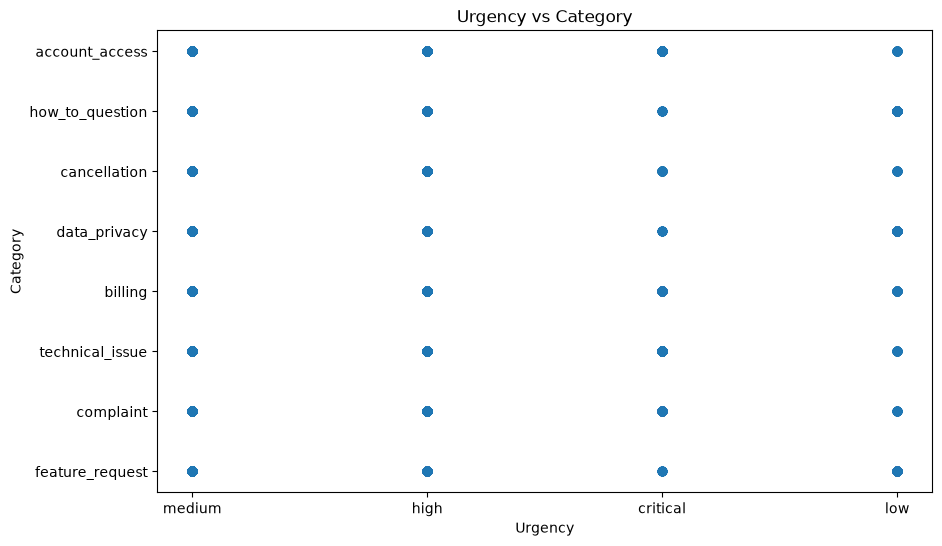

In [ ]:
#plot between urgency and category
plt.figure(figsize=(10, 6))
plt.scatter(data['urgency'], data['category'])
plt.xlabel('Urgency')
plt.ylabel('Category')
plt.title('Urgency vs Category')
plt.show()

In [184]:
pd.crosstab(
    data['category'],
    data['urgency'],
    normalize='index'
)

urgency,critical,high,low,medium
category,,,,
account_access,0.217331,0.422283,0.079780,0.280605
billing_cancellation,0.138199,0.389752,0.107919,0.364130
complaint_and_query,0.116175,0.313673,0.154602,0.415550
data_privacy,0.035985,0.246212,0.231061,0.486742
feature_request,0.039761,0.244533,0.230616,0.485089
technical_issue,0.203593,0.443114,0.067066,0.286228


In [86]:
#merge categories 
data['category'] = data['category'].replace({
'billing': 'billing_cancellation',
'cancellation': 'billing_cancellation',
'complaint': 'complaint_and_query', 
'how_to_question': 'complaint_and_query'})

In [87]:
data.head()

,ticket_id,subject,body,channel,customer_tier,created_at,category,urgency,assigned_team,language,resolution_status
0,TKT-001366,Request for custom fields in ticket view,Could you consider adding include JSON as an e...,web_form,pro,2025-04-03T07:41:06Z,feature_request,medium,product_team,en,pending
1,TKT-001137,Request for a clear status update,We rely on this service for daily work. differ...,chat,pro,2025-12-28T23:36:21Z,complaint_and_query,medium,success_team,en,open
2,TKT-001842,The issue keeps returning after repair,This has affected our team's work for several ...,phone,free,2025-06-08T19:28:12Z,complaint_and_query,high,success_team,en,resolved
3,TKT-002689,Search results are missing recent records,The problem started after the workspace was up...,chat,enterprise,2025-03-26T04:13:29Z,technical_issue,critical,engineering,en,escalated
4,TKT-002491,Tax amount seems incorrect on invoice,I noticed a receipt that never arrived on my a...,phone,free,2025-11-09T04:25:15Z,billing_cancellation,medium,billing_team,en,pending


In [88]:
from sklearn.preprocessing import LabelEncoder

In [89]:
cat_enc = LabelEncoder()
urg_enc = LabelEncoder()
data['y_category'] = cat_enc.fit_transform(data['category'])
data['y_urgency']  = urg_enc.fit_transform(data['urgency'])

In [90]:
print("Category classes:", list(cat_enc.classes_))
print("Urgency classes :", list(urg_enc.classes_))

Category classes: ['account_access', 'billing_cancellation', 'complaint_and_query', 'data_privacy', 'feature_request', 'technical_issue']
Urgency classes : ['critical', 'high', 'low', 'medium']


In [91]:
from sklearn.model_selection import train_test_split

# tokenize subject and body text

In [92]:
from tensorflow.keras.preprocessing.text import Tokenizer
tokenizer = Tokenizer()
data['text'] = data['subject'] + ' ' + data['body']
tokenizer.fit_on_texts(data['text'])
sequences = tokenizer.texts_to_sequences(data['text'])
max_text_len=max(len(data['text'][i]) for i in range(len(data['text'])))

max_text_len

273

In [93]:
#encoding the subject and body sequences using padding
from tensorflow.keras.preprocessing.sequence import pad_sequences
text_padded = pad_sequences(sequences, maxlen=max_text_len, padding='post')

In [94]:
import numpy as np
import tensorflow as tf
import mlflow

mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment("ticket_classification")

<Experiment: artifact_location='mlflow-artifacts:/1', creation_time=1793602115933, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1793602115933, lifecycle_stage='active', name='ticket_classification', tags={}, trace_location=None, workspace='default'>

In [95]:
category = data['y_category']
urgency = data['y_urgency']

In [96]:
category.unique()

array([4, 2, 5, 1, 3, 0])

In [97]:
category=np.array(category)
urgency=np.array(urgency)

In [98]:
padded_text = np.array(text_padded)

In [99]:
padded_text.shape

(5000, 273)

In [100]:
from sklearn.model_selection import train_test_split

In [101]:
X_train, X_test, yc_train, yc_test, yu_train, yu_test = train_test_split(
    padded_text, category, urgency,test_size=0.10, random_state=42)

In [109]:
X_train.shape

(4500, 273)

In [103]:
tokenizer.word_index



{'the': 1,
 'i': 2,
 'to': 3,
 'a': 4,
 'and': 5,
 'our': 6,
 'is': 7,
 'this': 8,
 'please': 9,
 'would': 10,
 'for': 11,
 'my': 12,
 'account': 13,
 'not': 14,
 'on': 15,
 'we': 16,
 'workspace': 17,
 'after': 18,
 'have': 19,
 'you': 20,
 'me': 21,
 'need': 22,
 'team': 23,
 'could': 24,
 'an': 25,
 'how': 26,
 'it': 27,
 'can': 28,
 'let': 29,
 'what': 30,
 'but': 31,
 'am': 32,
 'know': 33,
 'was': 34,
 'request': 35,
 'data': 36,
 'page': 37,
 'like': 38,
 'needs': 39,
 'has': 40,
 'of': 41,
 'invoice': 42,
 'work': 43,
 'because': 44,
 'steps': 45,
 'records': 46,
 'cannot': 47,
 'new': 48,
 'be': 49,
 'update': 50,
 'help': 51,
 'when': 52,
 'tried': 53,
 'several': 54,
 'product': 55,
 'in': 56,
 'renewal': 57,
 'if': 58,
 'information': 59,
 'access': 60,
 'more': 61,
 'plan': 62,
 'tell': 63,
 'before': 64,
 'same': 65,
 'email': 66,
 'billing': 67,
 'whether': 68,
 'no': 69,
 'appreciate': 70,
 'up': 71,
 'payment': 72,
 'expected': 73,
 'change': 74,
 'someone': 75,
 'expo

In [104]:
from tensorflow.keras import layers, Model

In [105]:
inputs = layers.Input(shape=(max_text_len,))

x = layers.Embedding(
    input_dim=len(tokenizer.word_index) + 1,
    output_dim=128
)(inputs)

x = layers.GlobalAveragePooling1D()(x)

x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)

x = layers.Dense(64, activation="relu")(x)

# Category prediction
category_output = layers.Dense(
    6, activation="softmax", name="category_output"
)(x)

# Urgency prediction
urgency_output = layers.Dense(
    4, activation="softmax", name="urgency_output"
)(x)

model = Model(
    inputs=inputs,
    outputs=[category_output, urgency_output]
)

In [106]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0007),

    loss={
        "category_output": "sparse_categorical_crossentropy",
        "urgency_output": "sparse_categorical_crossentropy"
    },

    metrics={
        "category_output": ["accuracy"],
        "urgency_output": ["accuracy"]
    }
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 273)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 273, 128)  │     69,888 │ input_layer_1[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ embedding_1[0][0] │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 128)       │     16,512 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 64)        │      8,256 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ category_output     │ (None, 6)         │        390 │ dense_3[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ urgency_output      │ (None, 4)         │        260 │ dense_3[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 95,306 (372.29 KB)

 Trainable params: 95,306 (372.29 KB)

 Non-trainable params: 0 (0.00 B)

In [107]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )
]

with mlflow.start_run():

    mlflow.log_params({
        "max_tokens": len(tokenizer.word_index) + 1,
        "max_length": max_text_len,
        "embedding_dim": 128,
        "batch_size": 32,
        "optimizer": "Adam",
        "epochs": 20
    })

    history = model.fit(
        X_train,
        {"category_output": yc_train, "urgency_output": yu_train},
        validation_split=0.1,
        epochs=20,
        batch_size=32,
        callbacks=callbacks
    )

    for metric, values in history.history.items():
        for epoch, value in enumerate(values):
            mlflow.log_metric(metric, float(value), step=epoch)

    model.save("ticket_classifier.keras")

Epoch 1/20
127/127 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - category_output_accuracy: 0.2622 - category_output_loss: 1.7374 - loss: 3.0188 - urgency_output_accuracy: 0.3775 - urgency_output_loss: 1.2804 - val_category_output_accuracy: 0.2089 - val_category_output_loss: 1.7465 - val_loss: 3.0271 - val_urgency_output_accuracy: 0.3667 - val_urgency_output_loss: 1.2758
Epoch 2/20
127/127 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - category_output_accuracy: 0.2726 - category_output_loss: 1.7083 - loss: 2.9831 - urgency_output_accuracy: 0.3706 - urgency_output_loss: 1.2740 - val_category_output_accuracy: 0.2089 - val_category_output_loss: 1.7162 - val_loss: 2.9898 - val_urgency_output_accuracy: 0.3667 - val_urgency_output_loss: 1.2754
Epoch 3/20
127/127 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - category_output_accuracy: 0.3459 - category_output_loss: 1.5733 - loss: 2.8431 - urgency_output_accuracy: 0.3904 - urgency_output_loss: 1.2685 - val_category_output_accuracy: 0.4467 - val_category_output_loss: 1.3163 - 

In [110]:
results = model.evaluate(
    X_test,
    {"category_output": yc_test, "urgency_output": yu_test},
    return_dict=True
)

print(results)

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - category_output_accuracy: 1.0000 - category_output_loss: 0.0034 - loss: 1.2301 - urgency_output_accuracy: 0.4360 - urgency_output_loss: 1.2264
{'category_output_accuracy': 1.0, 'category_output_loss': 0.0033597766887396574, 'loss': 1.2300702333450317, 'urgency_output_accuracy': 0.4359999895095825, 'urgency_output_loss': 1.2263635396957397}


# XGBoost plus TFIDF word embedding

In [113]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1,2)
)

X = vectorizer.fit_transform(data['text']).toarray()

In [115]:
X.shape

(5000, 2369)

In [202]:
urgency_encoding_map={'critical':3,'high':2,"medium":1,"low":0}
urgency=np.array(data['urgency'].replace(urgency_encoding_map),dtype=np.int64)

In [255]:
#updated encoding
urgency_encoding_map={'critical':2,'high':2,"medium":1,"low":0}
urgency=np.array(data['urgency'].replace(urgency_encoding_map),dtype=np.int64)

In [269]:
Y = np.column_stack([category, urgency])

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.50,
    random_state=42,
)

y_cat_train = Y_train[:, 0]
y_cat_test  = Y_test[:, 0]

y_urg_train = Y_train[:, 1]
y_urg_test  = Y_test[:, 1]

In [249]:
#smote only for experiment
from imblearn.over_sampling import SMOTE

smote = SMOTE(
    random_state=42,
    k_neighbors=5
)

X_train_smote, y_urg_train_smote = smote.fit_resample(
    X_train,
    y_urg_train
)

In [250]:
from collections import Counter

print(Counter(y_urg_train))
print(Counter(y_urg_train_smote))

Counter({np.int64(1): 1513, np.int64(2): 1400, np.int64(3): 550, np.int64(0): 537})
Counter({np.int64(0): 1513, np.int64(1): 1513, np.int64(3): 1513, np.int64(2): 1513})


In [251]:
urg_model = LogisticRegression(
    max_iter=5000,
    n_jobs=-1
)

urg_model.fit(
    X_train_smote,
    y_urg_train_smote
)

c:\Users\EMS\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",5000
,"n_jobs n_jobs: int, default=NoneDoes not have any effect... deprecated:: 1.8 `n_jobs` is deprecated in version 1.8 and will be removed in 1.10.",-1
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <rando

In [252]:
y_urg_test.shape

(1000,)

In [254]:
pred=urg_model.predict(X_test)
accuracy_score(pred,y_urg_test)

0.294

In [222]:
from sklearn.metrics import accuracy_score, classification_report
from sklearn.multioutput import MultiOutputClassifier
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier
from tensorflow.keras.layers import Input, Dense, Dropout

In [265]:
def evaluate_multioutput(y_true, y_pred):

    cat_acc = accuracy_score(
        y_true[:,0],
        y_pred[:,0]
    )

    urg_acc = accuracy_score(
        y_true[:,1],
        y_pred[:,1]
    )

    mean_acc = (cat_acc + urg_acc)/2

    return cat_acc, urg_acc, mean_acc

In [270]:
with mlflow.start_run(run_name="trainsplit50_LogisticRegression"):

    model = MultiOutputClassifier(
        LogisticRegression(
            max_iter=3000
        )
    )

    model.fit(X_train, Y_train)

    preds = model.predict(X_test)

    cat_acc, urg_acc, avg_acc = evaluate_multioutput(
        Y_test,
        preds
    )

    mlflow.log_param("model", "LogisticRegression")

    mlflow.log_metric("category_acc", cat_acc)
    mlflow.log_metric("urgency_acc", urg_acc)
    mlflow.log_metric("average_acc", avg_acc)

    mlflow.sklearn.log_model(model,"model")

2026/11/04 15:26:52 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run trainsplit50_LogisticRegression at: http://localhost:5000/#/experiments/1/runs/73ce35aa8c2b4d61929476ef0e993f3b
🧪 View experiment at: http://localhost:5000/#/experiments/1


In [278]:
pred=model.predict(X_test)

In [279]:
print(classification_report(pred[:,1],Y_test[:,1]))

              precision    recall  f1-score   support

           0       0.01      0.24      0.02        17
           1       0.45      0.45      0.45       916
           2       0.76      0.60      0.67      1567

    accuracy                           0.54      2500
   macro avg       0.41      0.43      0.38      2500
weighted avg       0.64      0.54      0.59      2500



# Using Neural Network 

In [165]:
n_features = X_train.shape[1]

inputs = Input(shape=(n_features,))

x = Dense(512, activation='relu')(inputs)
x = Dropout(0.3)(x)

x = Dense(256, activation='relu')(x)
x = Dropout(0.3)(x)

x = Dense(128, activation='relu')(x)

category_output = Dense(
    6,
    activation='softmax',
    name='category'
)(x)

urgency_output = Dense(
    4,
    activation='softmax',
    name='urgency'
)(x)

model = Model(
    inputs=inputs,
    outputs=[
        category_output,
        urgency_output
    ]
)

In [166]:
model.compile(
    optimizer='adam',
    loss={
        'category':'sparse_categorical_crossentropy',
        'urgency':'sparse_categorical_crossentropy'
    },
    metrics={
        'category':['accuracy'],
        'urgency':['accuracy']
    }
)

In [167]:
with mlflow.start_run(run_name="Keras_Multitask"):

    history = model.fit(
        X_train,
        {
            "category": y_cat_train,
            "urgency": y_urg_train
        },
        validation_split=0.10,
        epochs=20,
        batch_size=64,
        verbose=1
    )

    preds_cat, preds_urg = model.predict(X_test)

    cat_pred = np.argmax(preds_cat, axis=1)
    urg_pred = np.argmax(preds_urg, axis=1)

    cat_acc = accuracy_score(
        y_cat_test,
        cat_pred
    )

    urg_acc = accuracy_score(
        y_urg_test,
        urg_pred
    )

    avg_acc = (
        cat_acc + urg_acc
    ) / 2

    mlflow.log_param(
        "model",
        "keras_multitask"
    )

    mlflow.log_metric(
        "category_acc",
        cat_acc
    )

    mlflow.log_metric(
        "urgency_acc",
        urg_acc
    )

    mlflow.log_metric(
        "average_acc",
        avg_acc
    )

    mlflow.keras.log_model(
        model,
        "model"
    )

Epoch 1/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step - category_accuracy: 0.7531 - category_loss: 0.6260 - loss: 1.9236 - urgency_accuracy: 0.3981 - urgency_loss: 1.2887 - val_category_accuracy: 1.0000 - val_category_loss: 0.0019 - val_loss: 1.2846 - val_urgency_accuracy: 0.4000 - val_urgency_loss: 1.2906
Epoch 2/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - category_accuracy: 1.0000 - category_loss: 0.0053 - loss: 1.2489 - urgency_accuracy: 0.4314 - urgency_loss: 1.2411 - val_category_accuracy: 1.0000 - val_category_loss: 0.0039 - val_loss: 1.2562 - val_urgency_accuracy: 0.3925 - val_urgency_loss: 1.2617
Epoch 3/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - category_accuracy: 1.0000 - category_loss: 0.0062 - loss: 1.2181 - urgency_accuracy: 0.4342 - urgency_loss: 1.2116 - val_category_accuracy: 1.0000 - val_category_loss: 0.0031 - val_loss: 1.2491 - val_urgency_accuracy: 0.4350 - val_urgency_loss: 1.2540
Epoch 4/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - category_accuracy: 1.0000 - cate

2026/11/03 18:48:33 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/03 18:48:33 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.


🏃 View run Keras_Multitask at: http://localhost:5000/#/experiments/1/runs/ec25decef7a245abb3cf946fb1364399
🧪 View experiment at: http://localhost:5000/#/experiments/1


# Try only on urgency train

In [168]:
from sklearn.utils.class_weight import compute_class_weight

n_features = X_train.shape[1]

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(n_features,)),

    tf.keras.layers.Dense(512, activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.4),

    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(128, activation="relu"),

    tf.keras.layers.Dense(
        4,
        activation="softmax"
    )
])


In [169]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                 │ (None, 512)            │     1,213,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,381,252 (5.27 MB)

 Trainable params: 1,379,716 (5.26 MB)

 Non-trainable params: 1,536 (6.00 KB)

In [170]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

In [174]:
from sklearn.metrics import f1_score

In [175]:
with mlflow.start_run(run_name="Urgency_NN_only"):

    mlflow.log_params({
        "epochs": 50,
        "batch_size": 32,
        "optimizer": "Adam",
        "learning_rate": 1e-3,
        "dropout_1": 0.4,
        "dropout_2": 0.3
    })

    history = model.fit(
        X_train,
        Y_train[:, 1],
        validation_split=0.1,
        epochs=50,
        batch_size=32,
        callbacks=[
            early_stopping,
            reduce_lr
        ],
        verbose=1
    )

    y_prob = model.predict(X_test)

    y_pred = np.argmax(
        y_prob,
        axis=1
    )

    test_acc = accuracy_score(
        Y_test[:, 1],
        y_pred
    )

    macro_f1 = f1_score(
        Y_test[:, 1],
        y_pred,
        average="macro"
    )

    weighted_f1 = f1_score(
        Y_test[:, 1],
        y_pred,
        average="weighted"
    )

    mlflow.log_metric(
        "test_accuracy",
        test_acc
    )

    mlflow.log_metric(
        "macro_f1",
        macro_f1
    )

    mlflow.log_metric(
        "weighted_f1",
        weighted_f1
    )

    mlflow.keras.log_model(
        model,
        artifact_path="model"
    )

    print(
        classification_report(
            Y_test[:, 1],
            y_pred
        )
    )

Epoch 1/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.5089 - loss: 1.1067 - val_accuracy: 0.3975 - val_loss: 1.2950 - learning_rate: 6.2500e-05
Epoch 2/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.5075 - loss: 1.0979 - val_accuracy: 0.3700 - val_loss: 1.3144 - learning_rate: 6.2500e-05
Epoch 3/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.5122 - loss: 1.0887 - val_accuracy: 0.3700 - val_loss: 1.3303 - learning_rate: 6.2500e-05
Epoch 4/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.5308 - loss: 1.0747 - val_accuracy: 0.3700 - val_loss: 1.3375 - learning_rate: 3.1250e-05
Epoch 5/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.5183 - loss: 1.0738 - val_accuracy: 0.3700 - val_loss: 1.3424 - learning_rate: 3.1250e-05
Epoch 6/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.5267 - loss: 1.0672 - val_accuracy: 0.3725 - val_loss: 1.3439 - learning_rate: 1.5625e-05
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


2026/11/03 19:02:58 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/03 19:02:58 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.


              precision    recall  f1-score   support

           0       0.19      0.11      0.14       125
           1       0.43      0.56      0.49       383
           2       0.23      0.08      0.12       127
           3       0.45      0.47      0.46       365

    accuracy                           0.41      1000
   macro avg       0.32      0.31      0.30      1000
weighted avg       0.38      0.41      0.39      1000

🏃 View run Urgency_NN_only at: http://localhost:5000/#/experiments/1/runs/7cc0367e50734dff8e772aa396b17808
🧪 View experiment at: http://localhost:5000/#/experiments/1


In [62]:
def predict_ticket(subject, body):

    text = [str(subject) + " " + str(body)]
    sequence = tokenizer.texts_to_sequences(text)
    padded = pad_sequences(
        sequence,
        maxlen=max_text_len,
        padding="post"
    )
    category_pred, urgency_pred = model.predict(
        padded,
        verbose=0
    )
    category_id = np.argmax(category_pred[0])
    urgency_id = np.argmax(urgency_pred[0])

    category_name = cat_enc.inverse_transform([category_id])[0]
    urgency_name = urg_enc.inverse_transform([urgency_id])[0]

    return {
        "category": category_name,
        "urgency": urgency_name
    }

In [63]:
predict_ticket(
    "Payment failed",
    "I tried making a payment but the transaction failed. Money was deducted from my account."
)

{'category': 'billing_cancellation', 'urgency': 'high'}

In [271]:
import json
import os

ARTIFACT_DIR = "artifacts"

os.makedirs(ARTIFACT_DIR, exist_ok=True)


import joblib

joblib.dump(
    cat_enc,
    os.path.join(ARTIFACT_DIR, "category_encoder.pkl")
)
joblib.dump(
    model,
    "artifacts/model.pkl"
)

joblib.dump(
    vectorizer,
    "artifacts/tfidf.pkl"
)
config = {
    "max_text_len": int(max_text_len),
    "padding": "post",
    "text_combination": "subject + ' ' + body",
    "category_classes": cat_enc.classes_.tolist(),
    "urgency_classes": urg_enc.classes_.tolist()
}

with open(
    os.path.join(ARTIFACT_DIR, "config.json"),
    "w"
) as f:
    json.dump(config, f, indent=4)

Data inserted successfully!
